In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import umap
import numpy as np
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
import ee

In [2]:
sns.set_theme(style="darkgrid")

df = pd.read_csv("../data/pl2_adaptive.csv")

In [3]:
df_clean = df.dropna(subset=['label'])
print(f"Points after dropping nulls: {len(df_clean)}")
print(df_clean['label_name'].value_counts())

Points after dropping nulls: 90102
label_name
Tree cover                46151
Cropland                  31517
Grassland                  9903
Built-up                   1317
Permanent water bodies     1165
Bare/sparse vegetation       44
Herbaceous wetland            5
Name: count, dtype: int64


In [24]:
min_count = df_clean['label'].value_counts().min()
df_balanced = df_clean.groupby('label').sample(n=min_count, random_state=42)

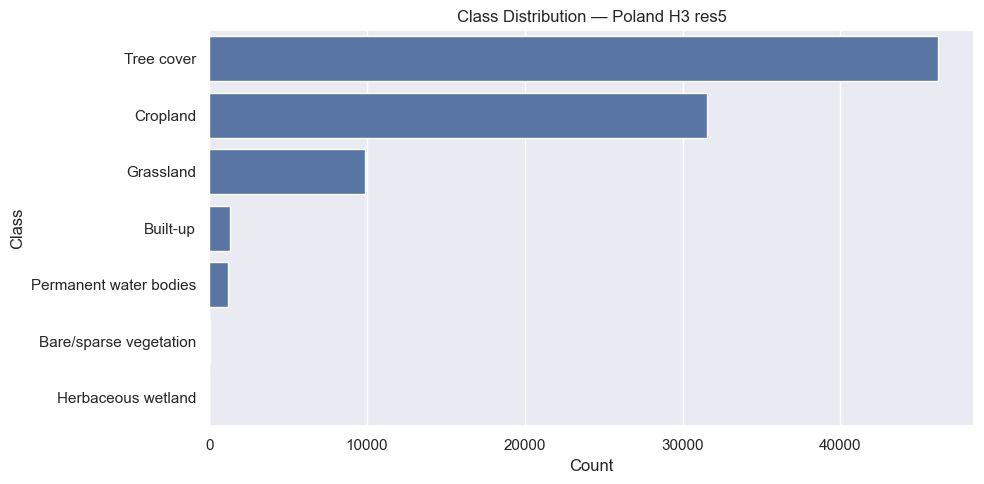

In [25]:
plt.figure(figsize=(10, 5))
order = df['label_name'].value_counts().index
sns.countplot(data=df, y='label_name', order=order)
plt.xlabel('Count')
plt.ylabel('Class')
plt.title('Class Distribution — Poland H3 res5')
plt.tight_layout()
plt.show()

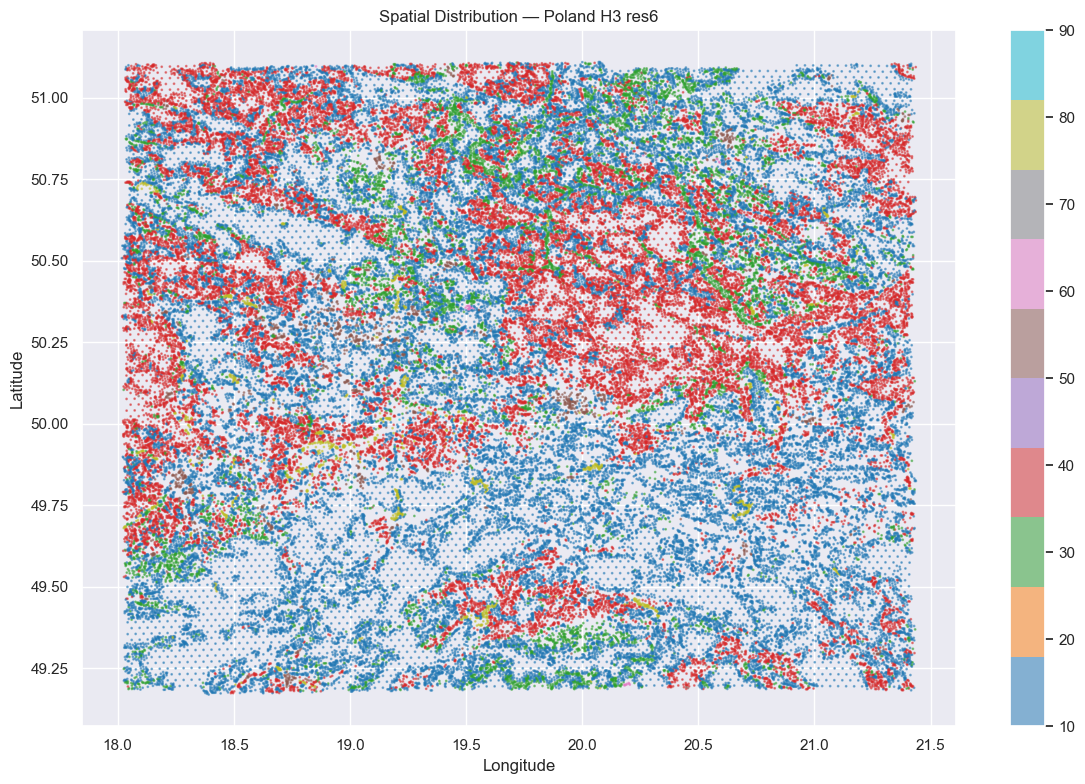

In [ ]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    df_clean['lon'], 
    df_clean['lat'],
    c=df_clean['label'],
    cmap='tab10',
    s=1,
    alpha=0.5
)
plt.colorbar(scatter)
plt.title('Spatial Distribution — Southern Poland (PL2) H3 res6')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


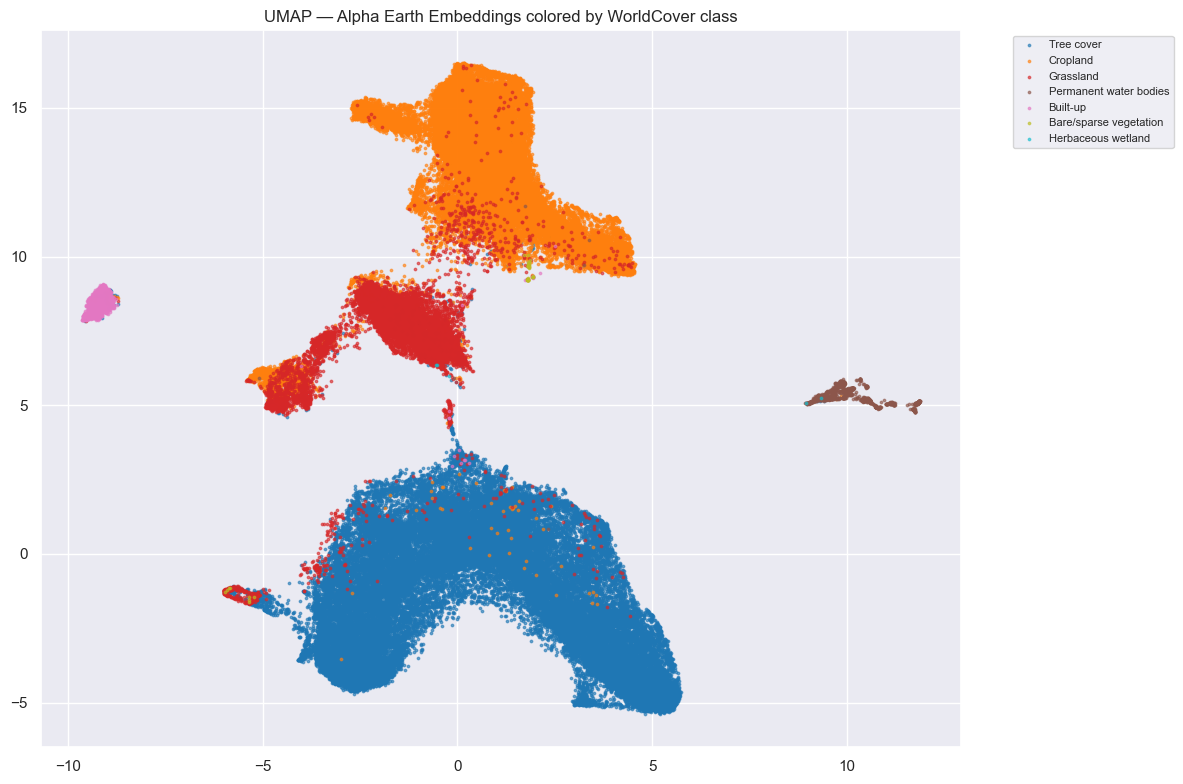

In [27]:
embedding_cols = [c for c in df_clean.columns if c.startswith('A')]
X = df_clean[embedding_cols].values
y = df_clean['label_name'].values

reducer = umap.UMAP(random_state=42, n_neighbors=15, min_dist=0.1)
embedding_2d = reducer.fit_transform(X)

plt.figure(figsize=(12, 8))
classes = df_clean['label_name'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

for cls, color in zip(classes, colors):
    mask = y == cls
    plt.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        c=[color],
        label=cls,
        s=3,
        alpha=0.6
    )

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.title('UMAP — Alpha Earth Embeddings colored by WorldCover class')
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'PCA — how many dimensions matter?')

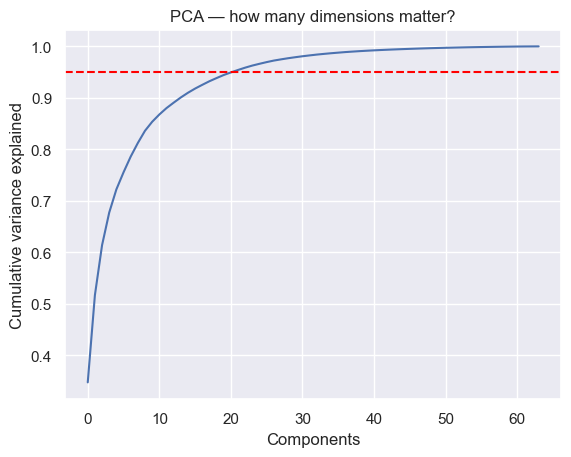

In [28]:
pca = PCA()
pca.fit(X)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Components')
plt.ylabel('Cumulative variance explained')
plt.axhline(0.95, color='red', linestyle='--', label='95%')
plt.title('PCA — how many dimensions matter?')

In [29]:
iso = IsolationForest(contamination=0.02, random_state=42)
outliers = iso.fit_predict(X)
print(f"Outliers detected: {(outliers == -1).sum()}")
df_clean = df_clean[outliers == 1]

Outliers detected: 1803


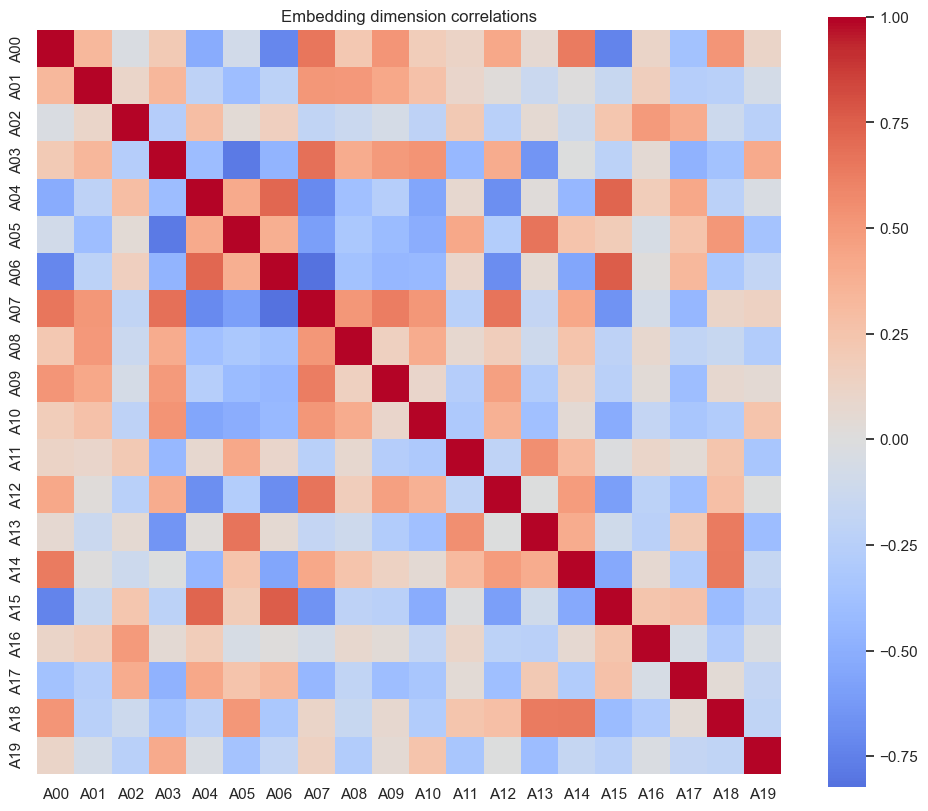

In [30]:
embed_cols = [c for c in df_clean.columns if c.startswith('A')][:20]
X_df = df_clean[embed_cols]
plt.figure(figsize=(12, 10))
sns.heatmap(X_df.corr(), cmap='coolwarm', center=0, square=True)
plt.title('Embedding dimension correlations')
plt.show()

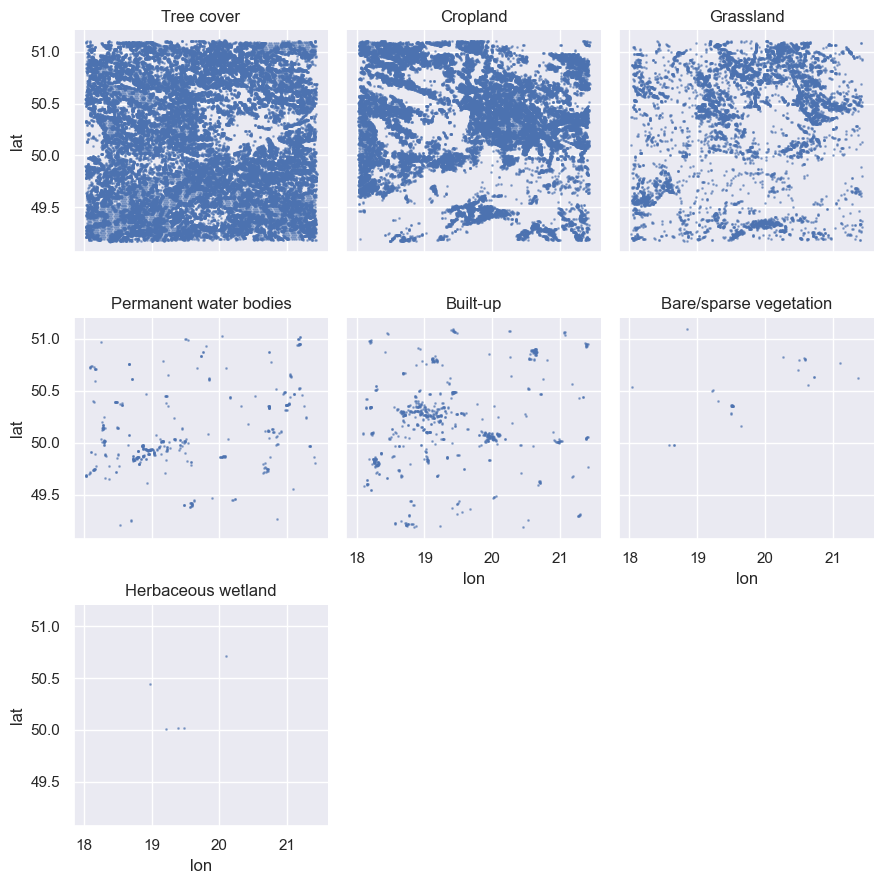

In [31]:
g = sns.FacetGrid(df_clean, col='label_name', col_wrap=3, height=3)
g.map(plt.scatter, 'lon', 'lat', s=1, alpha=0.5)
g.set_titles('{col_name}')
plt.show()

In [32]:
def prepare_ml_dataset(df, min_samples=50, max_samples=500, random_state=42):
    """
    Prepare balanced ML-ready dataset from raw embeddings.
    
    Args:
        min_samples: drop classes below this threshold
        max_samples: cap classes above this threshold
        random_state: for reproducibility
    """
    df = df.dropna(subset=['label']).copy()
    
    class_counts = df['label'].value_counts()
    valid = class_counts[class_counts >= min_samples].index
    df = df[df['label'].isin(valid)]
    
    df = df.groupby('label').apply(
        lambda x: x.sample(min(len(x), max_samples), random_state=random_state)
    ).reset_index(drop=True)
    
    print(f"Classes: {df['label_name'].nunique()}")
    print(df['label_name'].value_counts())
    print(f"Total points: {len(df)}")
    
    return df

df_ml = prepare_ml_dataset(df_clean, min_samples=50, max_samples=500)

Classes: 5
label_name
Tree cover                500
Grassland                 500
Cropland                  500
Built-up                  500
Permanent water bodies    455
Name: count, dtype: int64
Total points: 2455


In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

MIN_SAMPLES = 20

embedding_cols = [c for c in df_ml.columns if c.startswith('A')]
X = df_ml[embedding_cols].values
y = df_ml['label_name'].values

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Classes: {le.classes_}")

Train: (1964, 64), Test: (491, 64)
Classes: ['Built-up' 'Cropland' 'Grassland' 'Permanent water bodies' 'Tree cover']


In [38]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, 
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, 
        random_state=42, 
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{name} — Test accuracy: {model.score(X_test, y_test):.3f}")
    print(classification_report(y_test, y_pred, target_names=le.classes_))


Logistic Regression — Test accuracy: 0.971
                        precision    recall  f1-score   support

              Built-up       1.00      0.99      0.99       100
              Cropland       0.98      0.94      0.96       100
             Grassland       0.90      0.99      0.94       100
Permanent water bodies       0.99      0.99      0.99        91
            Tree cover       1.00      0.95      0.97       100

              accuracy                           0.97       491
             macro avg       0.97      0.97      0.97       491
          weighted avg       0.97      0.97      0.97       491


Random Forest — Test accuracy: 0.986
                        precision    recall  f1-score   support

              Built-up       1.00      1.00      1.00       100
              Cropland       0.98      0.98      0.98       100
             Grassland       0.95      0.99      0.97       100
Permanent water bodies       1.00      0.99      0.99        91
            Tree c

In [44]:
import ee
import numpy as np
import pandas as pd
from utilities.grid import KroneckerGridBuilder
from utilities.data_sources import AlphaEarth, ESAWorldCover
from utilities.data_builder import DatasetBuilder
ee.Initialize(project='lucera-494618')

MAZOWIECKIE_BBOX = (19.3, 51.0, 23.0, 53.5)

validation_dataset = (
    DatasetBuilder()
    .from_grid(KroneckerGridBuilder(bbox=MAZOWIECKIE_BBOX, n_points=1000))
    .set_label_source(ESAWorldCover())
    .add_source(AlphaEarth(year=2023))
    .build(strategy='standard')
    .save("data/mazowieckie_validation.csv")
)

Building standard dataset from 1000 points...


Fetching AlphaEarth embeddings: 100%|██████████| 2/2 [00:24<00:00, 12.27s/it]

Dataset built — 1000 rows, 68 columns
Saved to data/mazowieckie_validation.csv


In [46]:
df_val = pd.read_csv("data/mazowieckie_validation.csv")
df_val = df_val.dropna(subset=['label'])

known_classes = le.classes_
df_val = df_val[df_val['label_name'].isin(known_classes)]

embedding_cols = [c for c in df_val.columns if c.startswith('A')]
X_val = df_val[embedding_cols].values
y_val = le.transform(df_val['label_name'].values)

y_pred = models["Random Forest"].predict(X_val)
print(f"Validation accuracy (Mazowieckie): {(y_pred == y_val).mean():.3f}")
print(classification_report(y_val, y_pred, target_names=le.classes_))

Validation accuracy (Mazowieckie): 0.854
                        precision    recall  f1-score   support

              Built-up       0.53      0.84      0.65        32
              Cropland       0.82      0.97      0.89       339
             Grassland       0.83      0.69      0.76       241
Permanent water bodies       1.00      1.00      1.00        14
            Tree cover       0.95      0.85      0.90       370

              accuracy                           0.85       996
             macro avg       0.83      0.87      0.84       996
          weighted avg       0.87      0.85      0.85       996

